In [313]:
class Value:
    def __init__(self, p_value, p_history = [], p_tag = "", p_ops = "", p_children = []):
        self.value = p_value
        self.history = p_history
        self.tag = p_tag
        self.grad = 0 
        self.ops = p_ops
        self.children = p_children
        self.backprop = lambda: None 
        self.done = False 

    def __add__ (self, p_operand):
        self.ops = '+'
        h = [[[self.tag,self.value], [p_operand.tag,p_operand.value],[self.ops]]]
        h.extend(self.history)
        ret = Value(self.value + p_operand.value, h, p_children=[self, p_operand])
        ret.children=[self, p_operand]

        def _backprop():
            ret.children[0].grad = ret.grad * 1
            ret.children[1].grad = ret.grad * 1

        ret.backprop = _backprop
        return ret 

    def __sub__ (self, p_operand):
        self.ops = '-'
        h = [[[self.tag,self.value], [p_operand.tag,p_operand.value],[self.ops]]]
        h.extend(self.history)
        ret = Value(self.value - p_operand.value, h, p_children=[self, p_operand])
        ret.children=[self, p_operand]

        def _backprop():
            ret.children[0].grad = ret.grad * -1
            ret.children[1].grad = ret.grad * -1

        ret.backprop = _backprop
        return ret 

    def __mul__ (self, p_operand):
        self.ops = '*'
        h = [[[self.tag,self.value], [p_operand.tag,p_operand.value],[self.ops]]]
        h.extend(self.history)
        ret = Value(self.value * p_operand.value, h, p_children=[self, p_operand])
        ret.children = [self, p_operand]

        def _backprop():
            ret.children[0].grad = ret.grad * ret.children[1].value
            ret.children[1].grad = ret.grad * ret.children[0].value

        ret.backprop = _backprop
        return ret 

    def backward(self, p_start_grad=0):
        self.grad = p_start_grad
        self.backprop()
        self.done = True 
        for lp in range(len(self.children)):
            self.children[lp].backward(self.children[lp].grad)
            self.children[lp].done = True
    
    def __str__(self):
        return str(self.value)

    def __len__(self):
        return len(self.history)


In [314]:
a = Value(5, p_tag='a')
b = Value(1, p_tag='b')
c = Value(1, p_tag='c')
d = Value(9, p_tag='d')
e = a + b; e.tag='e'
f = e + c; f.tag='f'
g = f * d; g.tag='g'
print("a =", a, a.history)
print("b =", b, b.history)
print("c =", c, c.history)
print("d =", d, d.history)
print("e =", e, e.history)
print("f =", f, f.history)
print("g =", g, g.history)
g.backward(1)
print("a =", a, a.grad)
print("b =", b, b.grad)
print("c =", c, c.grad)
print("d =", d, d.grad)
print("e =", e, e.grad)
print("f =", f, f.grad)
print("g =", g, g.grad)


a = 5 []
b = 1 []
c = 1 []
d = 9 []
e = 6 [[['a', 5], ['b', 1], ['+']]]
f = 7 [[['e', 6], ['c', 1], ['+']], [['a', 5], ['b', 1], ['+']]]
g = 63 [[['f', 7], ['d', 9], ['*']], [['e', 6], ['c', 1], ['+']], [['a', 5], ['b', 1], ['+']]]
a = 5 9
b = 1 9
c = 1 9
d = 9 7
e = 6 9
f = 7 9
g = 63 1


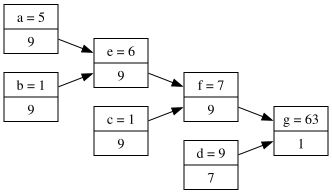

In [332]:
import mygraph
import importlib

importlib.reload(mygraph) #only for debugging. otherwise, you have to reload entire module
from mygraph import NNGraph

cdot = NNGraph([a,b,c,d,e,f,g]).gv_graph()
cdot